# EnergyPulse AI - Notebook 2: Model Training and Evaluation

Input: `../data/features.csv.gz`, made by **Notebook 1**.

| Step | What we do |
|---|---|
| 1 | Load the data and choose how we measure the error |
| 2 | Baseline: a simple rule to compare with |
| 3 | Train the model (XGBoost) and choose its settings on the validation set |
| 4 | Final evaluation on the test year (2014) |
| 5 | Understand the results |
| 6 | From forecast to alerts |
| 7 | Save the model |

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor

DATA_DIR = Path("../data")
OUT_DIR = Path("../outputs")
(OUT_DIR / "models").mkdir(parents=True, exist_ok=True)

FEATURES = ["lag_24", "lag_48", "lag_168", "mean_prev_day", "hour", "dayofweek", "month"]
TARGET = "y"            # consumption divided by the meter's training average (see Notebook 1, step 8)

data = pd.read_csv(DATA_DIR / "features.csv.gz", index_col="timestamp", parse_dates=True)
train = data[data.set == "train"].copy()
val   = data[data.set == "val"].copy()
test  = data[data.set == "test"].copy()
print(f"train {len(train):,} rows | validation {len(val):,} rows | test {len(test):,} rows | meters: {data.meter.nunique()}")

train 259,200 rows | validation 88,320 rows | test 175,200 rows | meters: 20


## 1. How we measure the error

All errors are computed in **kWh** (we multiply the scaled prediction back by the meter's scale).

| Metric | Formula | Meaning |
|---|---|---|
| **MAE** | mean of \|actual - predicted\| | average miss per hour, in kWh |
| **RMSE** | square root of mean of (actual - predicted)^2 | like MAE, but big misses count more |
| **WAPE** | sum of \|actual - predicted\| / sum of actual x 100 | the miss as a % of consumption |

**WAPE is our main metric.** Our meters go from 6 to 2,500 kWh per hour, so an error of 10 kWh is huge for the
small meter and tiny for the large one. WAPE is a percentage, so we can compare and average it across meters.
We do not use MAPE because it divides by every single value and explodes when a value is close to 0.

We compute the metrics **for each meter**, then take the **average over the 20 meters**.

In [2]:
def evaluate(df, column):
    # MAE, RMSE and WAPE of the prediction in `column` (kWh), one row per meter
    err = df["kwh"] - df[column]
    g = pd.DataFrame({"abs_err": err.abs(), "sq_err": err ** 2, "kwh": df["kwh"]}).groupby(df["meter"])
    return pd.DataFrame({
        "MAE":  g["abs_err"].mean(),
        "RMSE": np.sqrt(g["sq_err"].mean()),
        "WAPE": g["abs_err"].sum() / g["kwh"].sum() * 100,
    })

## 2. Baseline: "same hour yesterday"

The simplest forecast for tomorrow at 14:00 is **today's consumption at 14:00**.
It needs no training. If our model cannot beat this rule, the model is not useful.

In [3]:
for df in (train, val, test):
    df["baseline"] = df["lag_24"] * df["scale"]          # back to kWh

evaluate(val, "baseline").mean().round(2).rename("baseline on validation")

MAE     30.05
RMSE    50.43
WAPE     8.88
Name: baseline on validation, dtype: float64

## 3. The model: XGBoost

**Why XGBoost?**
- Our data is a **table** of features. Gradient-boosted trees are one of the strongest methods for tables.
- It learns **non-linear** patterns and combinations by itself, for example "Sunday at 10:00 is low, Monday at 10:00 is high".
- It is fast to train on our 260,000 training rows and needs no extra scaling.

**How it works, shortly:** it builds many small decision trees one after another.
Each new tree tries to correct the errors of the trees before it. The final prediction is the sum of all trees.

**Training:** one model for all 20 meters, on the scaled target `y`.

**Choosing the settings on the validation set:**
- `learning_rate = 0.05`: each tree only corrects a small part of the error (safer).
- `max_depth`: how deep each tree can be. We try **4, 6 and 8**.
- **Early stopping:** we keep adding trees while the validation error goes down, and stop after 50 trees with no improvement.

The test year is **not used** here.

In [4]:
results = []
models = {}
for depth in [4, 6, 8]:
    model = XGBRegressor(n_estimators=2000, learning_rate=0.05, max_depth=depth,
                         early_stopping_rounds=50, random_state=42, n_jobs=-1)
    model.fit(train[FEATURES], train[TARGET], eval_set=[(val[FEATURES], val[TARGET])], verbose=False)
    val["pred"] = model.predict(val[FEATURES]) * val["scale"]
    results.append({"max_depth": depth, "trees": model.best_iteration + 1,
                    "validation WAPE %": evaluate(val, "pred")["WAPE"].mean()})
    models[depth] = model

results = pd.DataFrame(results).set_index("max_depth")
best_depth = results["validation WAPE %"].idxmin()
model = models[best_depth]
print("Chosen max_depth:", best_depth)
results.round(3)

Chosen max_depth: 4


,trees,validation WAPE %
max_depth,,
4,116,8.565
6,75,8.616
8,79,8.582


In [5]:
val["xgb"] = model.predict(val[FEATURES]) * val["scale"]
pd.DataFrame({"Baseline (same hour yesterday)": evaluate(val, "baseline").mean(),
              "XGBoost": evaluate(val, "xgb").mean()}).T.round(2)

,MAE,RMSE,WAPE
Baseline (same hour yesterday),30.05,50.43,8.88
XGBoost,26.95,43.15,8.56


## 4. Final evaluation on the test year (2014)

Now we use the test set **once**. The model and its settings are fixed, nothing is changed after this point.

In [6]:
test["xgb"] = np.maximum(model.predict(test[FEATURES]) * test["scale"], 0)   # consumption cannot be negative

per_meter_base = evaluate(test, "baseline")
per_meter_xgb = evaluate(test, "xgb")

summary = pd.DataFrame({"Baseline (same hour yesterday)": per_meter_base.mean(),
                        "XGBoost": per_meter_xgb.mean()}).T
summary["WAPE improvement %"] = [np.nan, (1 - summary.loc["XGBoost", "WAPE"] / summary.loc["Baseline (same hour yesterday)", "WAPE"]) * 100]
summary.round(2)

,MAE,RMSE,WAPE,WAPE improvement %
Baseline (same hour yesterday),28.68,46.61,9.31,NaN
XGBoost,24.91,38.24,8.48,8.9


In [7]:
per_meter = pd.DataFrame({
    "mean kWh/h": test.groupby("meter")["kwh"].mean(),
    "baseline WAPE %": per_meter_base["WAPE"],
    "XGBoost WAPE %": per_meter_xgb["WAPE"],
}).sort_values("mean kWh/h")
per_meter["XGBoost better"] = per_meter["XGBoost WAPE %"] < per_meter["baseline WAPE %"]
print("XGBoost is better than the baseline on", int(per_meter["XGBoost better"].sum()), "of", len(per_meter), "meters")
per_meter.round(2)

XGBoost is better than the baseline on 18 of 20 meters


,mean kWh/h,baseline WAPE %,XGBoost WAPE %,XGBoost better
meter,,,,
MT_007,5.86,26.30,26.77,False
MT_016,32.91,11.54,9.93,True
MT_042,44.81,10.66,8.82,True
MT_051,55.99,12.12,10.46,True
MT_304,62.89,7.52,6.56,True
MT_315,82.25,4.33,3.62,True
MT_237,84.10,5.67,5.18,True
MT_356,89.09,18.77,19.57,False
MT_243,118.44,7.59,6.43,True


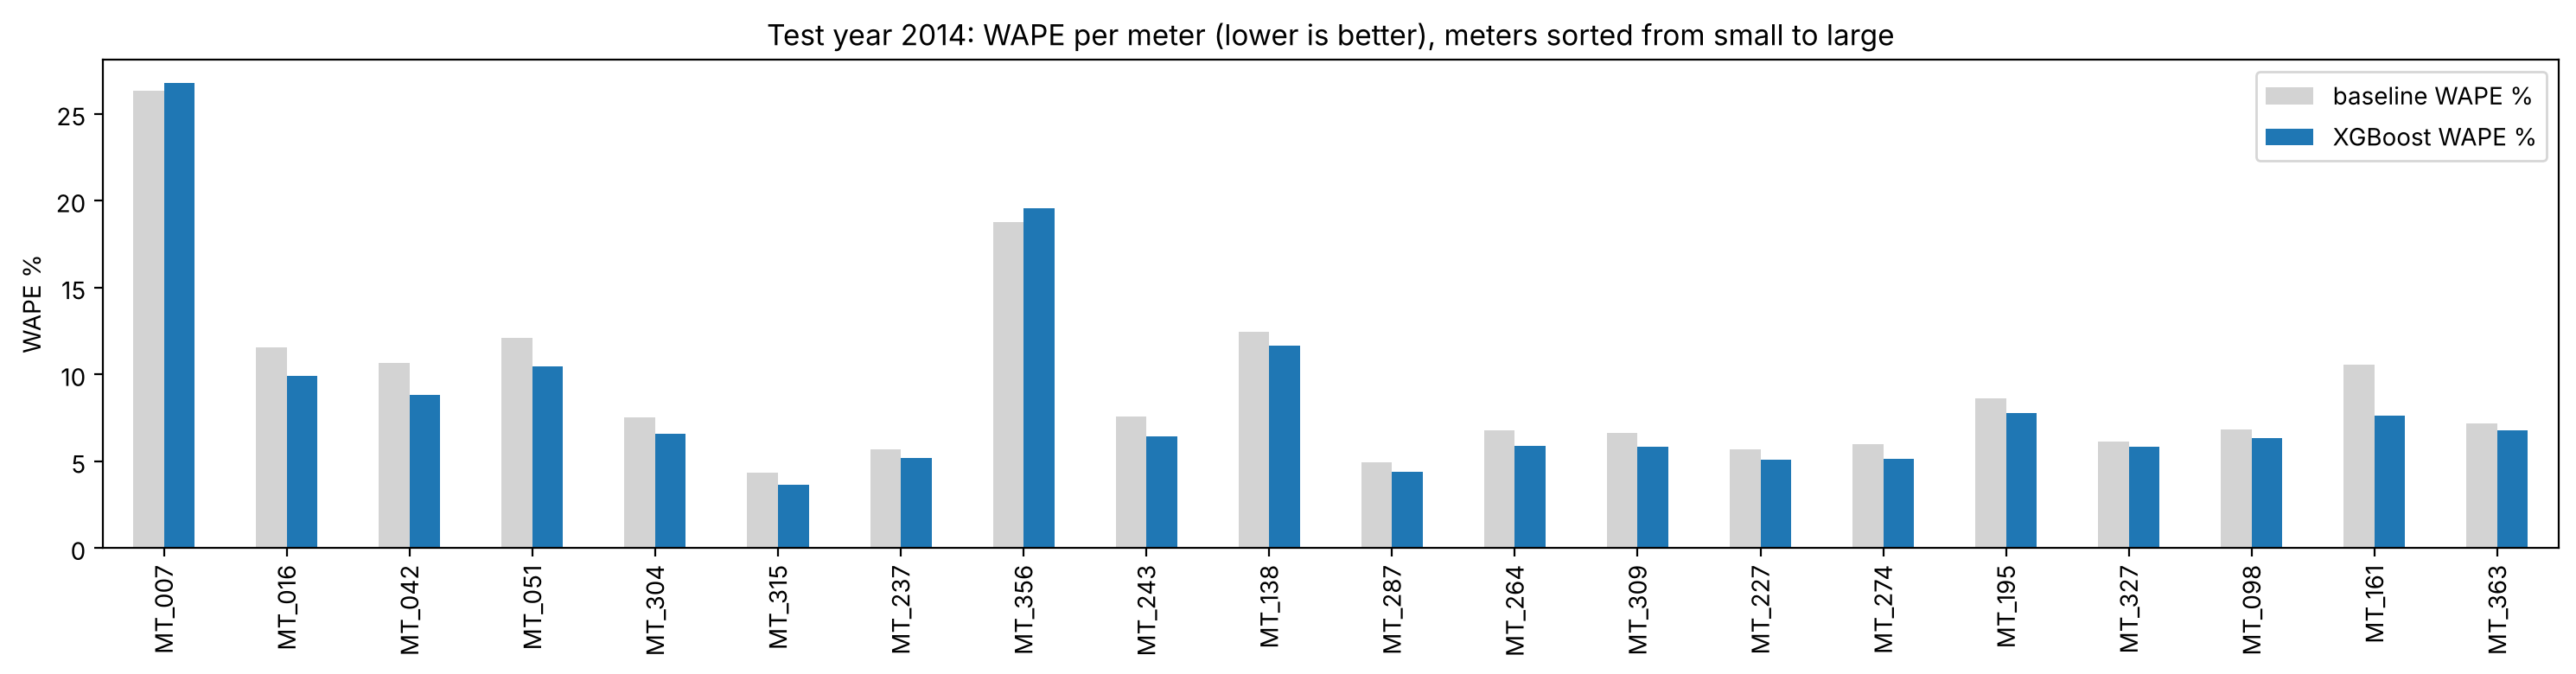

In [8]:
ax = per_meter[["baseline WAPE %", "XGBoost WAPE %"]].plot(kind="bar", figsize=(15, 4), color=["lightgray", "tab:blue"])
ax.set_title("Test year 2014: WAPE per meter (lower is better), meters sorted from small to large")
ax.set_ylabel("WAPE %"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

## 5. Understanding the results

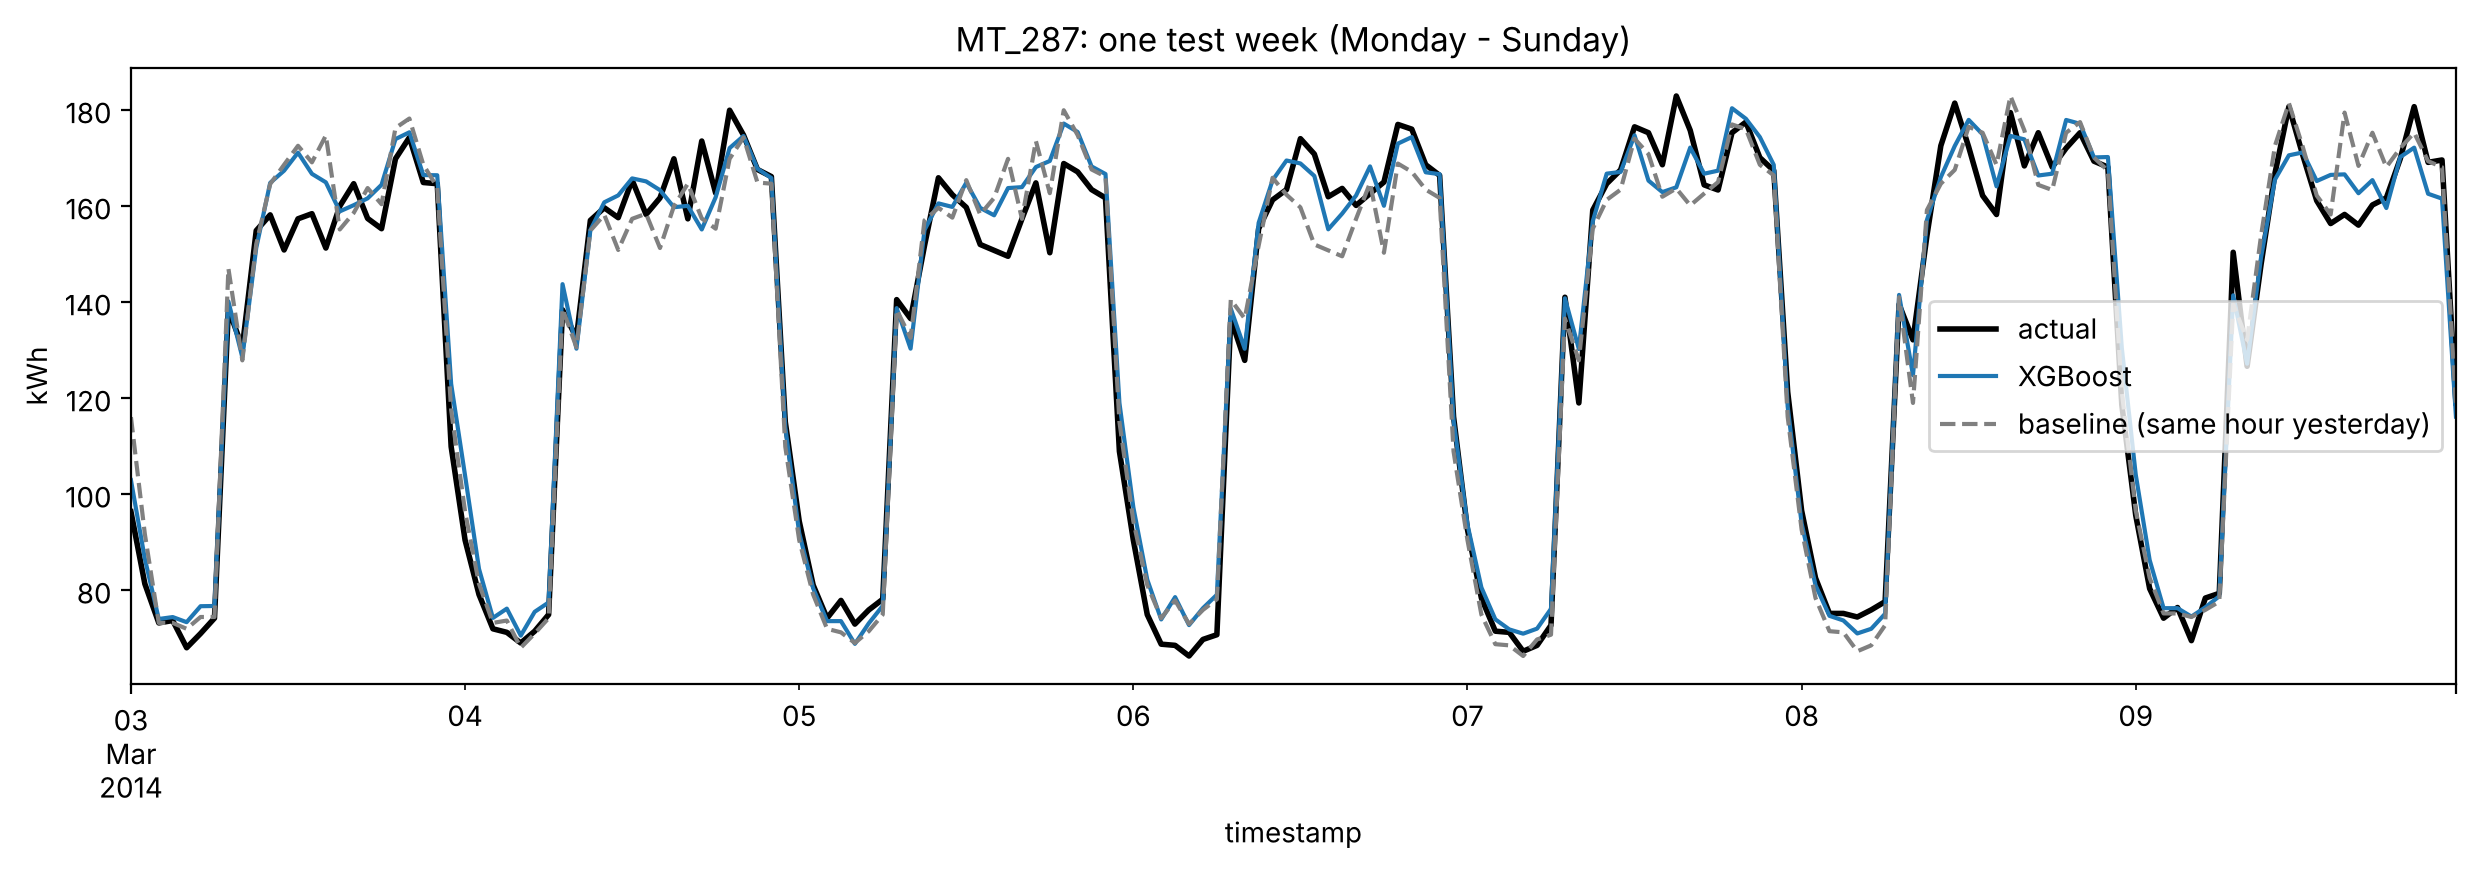

In [9]:
m = "MT_287"
week = test[test.meter == m].loc["2014-03-03":"2014-03-09"]
ax = week["kwh"].plot(figsize=(15, 4), color="black", lw=2, label="actual")
week["xgb"].plot(ax=ax, color="tab:blue", label="XGBoost")
week["baseline"].plot(ax=ax, color="gray", ls="--", label="baseline (same hour yesterday)")
ax.set_title(f"{m}: one test week (Monday - Sunday)"); ax.set_ylabel("kWh"); ax.legend(); plt.show()

The model (blue) follows the real consumption (black) closely: the low nights, the jump in the morning and the drop in the evening. The baseline (dashed) copies yesterday, so it repeats yesterday's small ups and downs even when they do not happen again.

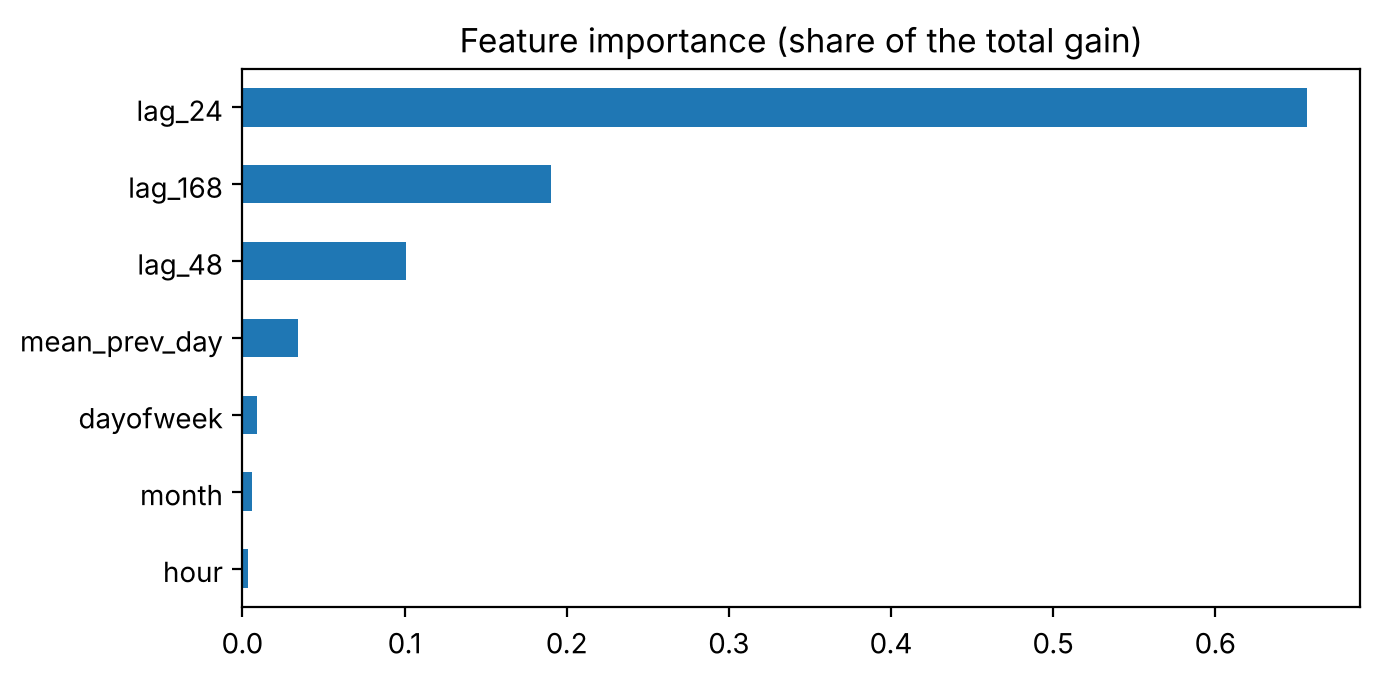

In [10]:
importance = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
ax = importance.plot(kind="barh", figsize=(7, 3.5))
ax.set_title("Feature importance (share of the total gain)"); plt.tight_layout(); plt.show()

**`lag_24`** (same hour yesterday) is by far the most useful feature, then **`lag_168`** (same hour last week) and **`lag_48`**. This matches what we saw in Notebook 1: consumption repeats every day and every week. `hour`, `dayofweek` and `month` get a small share because the lags already carry most of the daily and weekly pattern, but the model still uses them, for example to know that today is Monday (see the next plot).

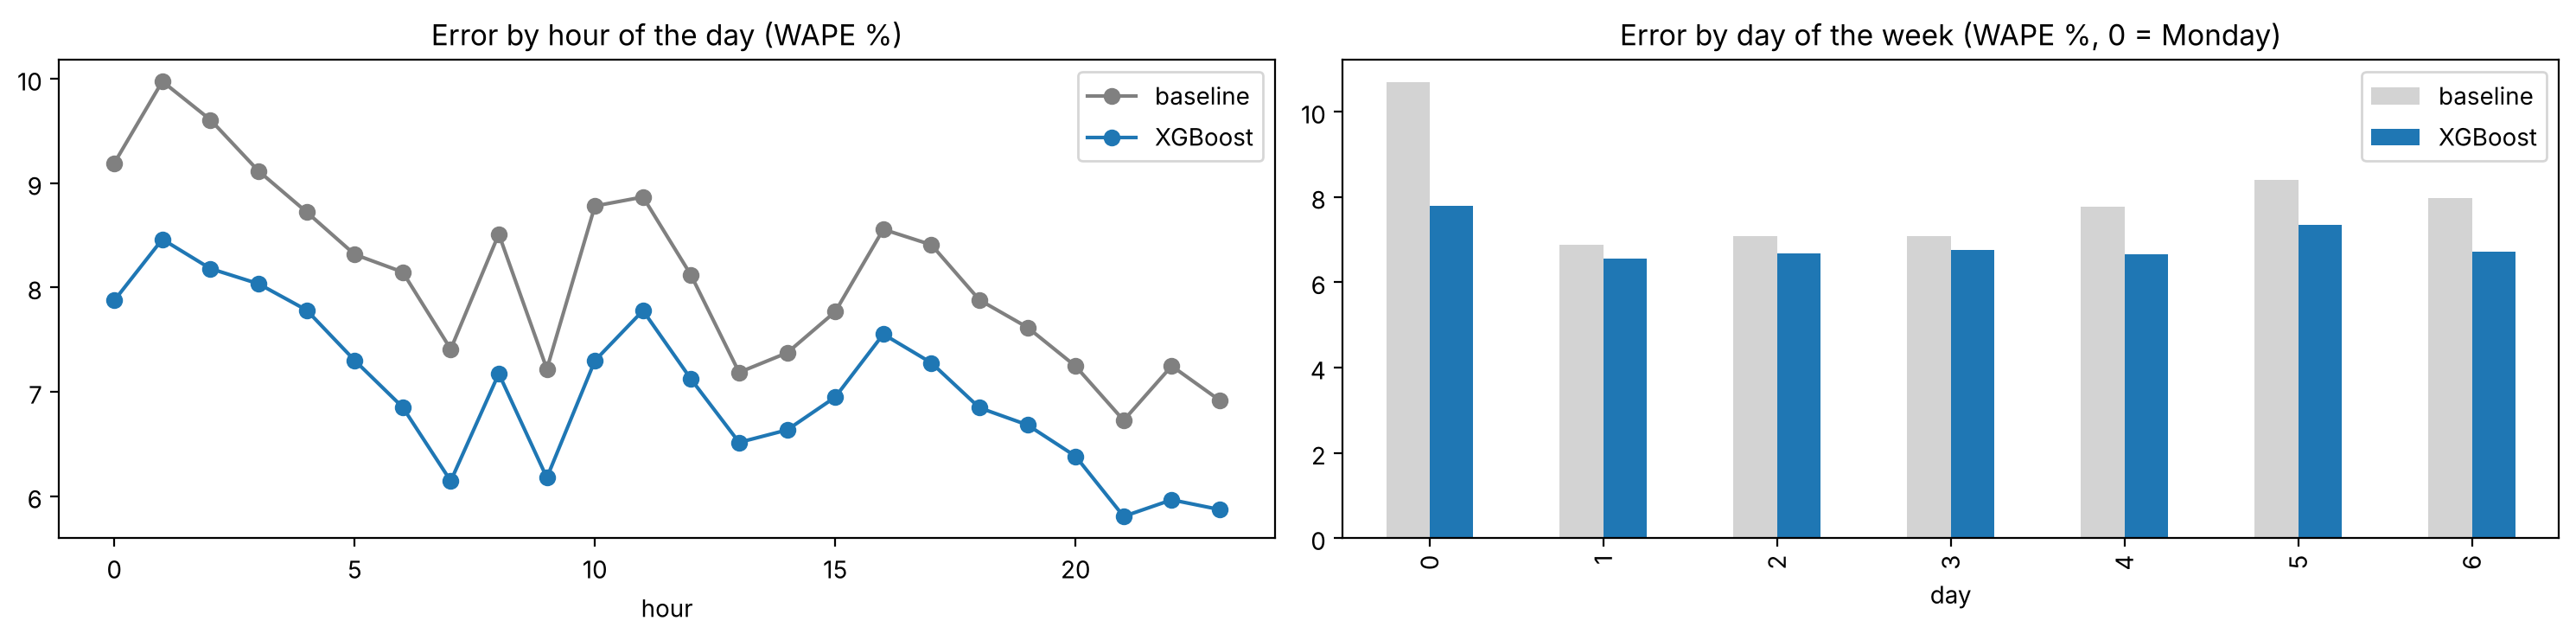

In [11]:
by_hour = pd.DataFrame({
    "baseline": test.assign(e=(test.kwh - test.baseline).abs()).groupby(test.index.hour).e.sum(),
    "XGBoost":  test.assign(e=(test.kwh - test.xgb).abs()).groupby(test.index.hour).e.sum(),
}).div(test.groupby(test.index.hour).kwh.sum(), axis=0) * 100
by_day = pd.DataFrame({
    "baseline": test.assign(e=(test.kwh - test.baseline).abs()).groupby(test.index.dayofweek).e.sum(),
    "XGBoost":  test.assign(e=(test.kwh - test.xgb).abs()).groupby(test.index.dayofweek).e.sum(),
}).div(test.groupby(test.index.dayofweek).kwh.sum(), axis=0) * 100

fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))
by_hour.plot(ax=ax[0], marker="o", color=["gray", "tab:blue"]); ax[0].set_title("Error by hour of the day (WAPE %)"); ax[0].set_xlabel("hour")
by_day.plot(ax=ax[1], kind="bar", color=["lightgray", "tab:blue"]); ax[1].set_title("Error by day of the week (WAPE %, 0 = Monday)"); ax[1].set_xlabel("day")
plt.tight_layout(); plt.show()

### Interpretation

- **The model beats the baseline.** On the test year 2014 the average WAPE goes from **9.3 % to 8.5 %** (about **9 % less error**). MAE goes from about 28.7 to 24.9 kWh per hour (about 13 % less) and RMSE from 46.6 to 38.2 (about 18 % less). RMSE improves the most, so the model mainly removes the **big misses**.
- **It wins on 18 of the 20 meters.** The two meters where it does not win (MT_007 and MT_356) are irregular meters with a high error for both methods (about 19 % to 27 %). Their consumption does not follow a clear daily pattern, so it is hard to predict with any method.
- **Biggest gain on Mondays.** The baseline predicts Monday from Sunday, so it is wrong when work starts again. The model also looks at last week (`lag_168`) and the day of the week, so its Monday error is much lower. The gain is also clear on Saturdays and Sundays.
- **No overfitting.** The WAPE on validation (8.6 %) and on test (8.5 %) are almost the same. The test year was never used for training or for choosing the settings, so this is a fair estimate of the error on new data.
- **The settings matter little.** `max_depth` 4, 6 and 8 give almost the same validation error, so the result does not depend on a lucky choice.
- **Limits.** The model does not know about public holidays, weather or special events. In practice: for a typical meter it misses by about 8 % of the consumption, one day ahead.

## 6. From forecast to alerts

The forecast tells us how much a meter **should** use. If the real reading is far from the forecast, something
unusual may be happening (equipment left on, a fault, a holiday). This is the **alert** shown in the app.

**Rule:**
1. On the **validation** period we look at the normal size of the forecast error of each meter: its standard deviation (std).
2. An hour is flagged when **\|actual - forecast\| > 3 x std** of that meter.

The threshold is computed on the validation period and only **applied** to 2014.

In [12]:
val_error_std = (val["kwh"] - val["xgb"]).groupby(val["meter"]).std()
test["threshold"] = test["meter"].map(3 * val_error_std)
test["flag"] = (test["kwh"] - test["xgb"]).abs() > test["threshold"]

print(f"Flagged hours in 2014: {test.flag.sum():,} of {len(test):,} ({test.flag.mean() * 100:.1f} %)")
print(f"About {test.flag.sum() / data.meter.nunique() / 12:.0f} flagged hours per meter per month")
test.groupby("meter").flag.mean().mul(100).round(1).rename("flagged hours %").sort_values().to_frame().T

Flagged hours in 2014: 1,801 of 175,200 (1.0 %)
About 8 flagged hours per meter per month


meter,MT_051,MT_098,MT_243,MT_237,MT_287,MT_042,MT_195,MT_138,MT_309,MT_304,MT_227,MT_315,MT_363,MT_274,MT_327,MT_264,MT_007,MT_161,MT_016,MT_356
flagged hours %,0.2,0.6,0.6,0.6,0.7,0.8,0.9,0.9,0.9,0.9,0.9,0.9,1.0,1.0,1.3,1.4,1.5,1.5,1.7,2.1


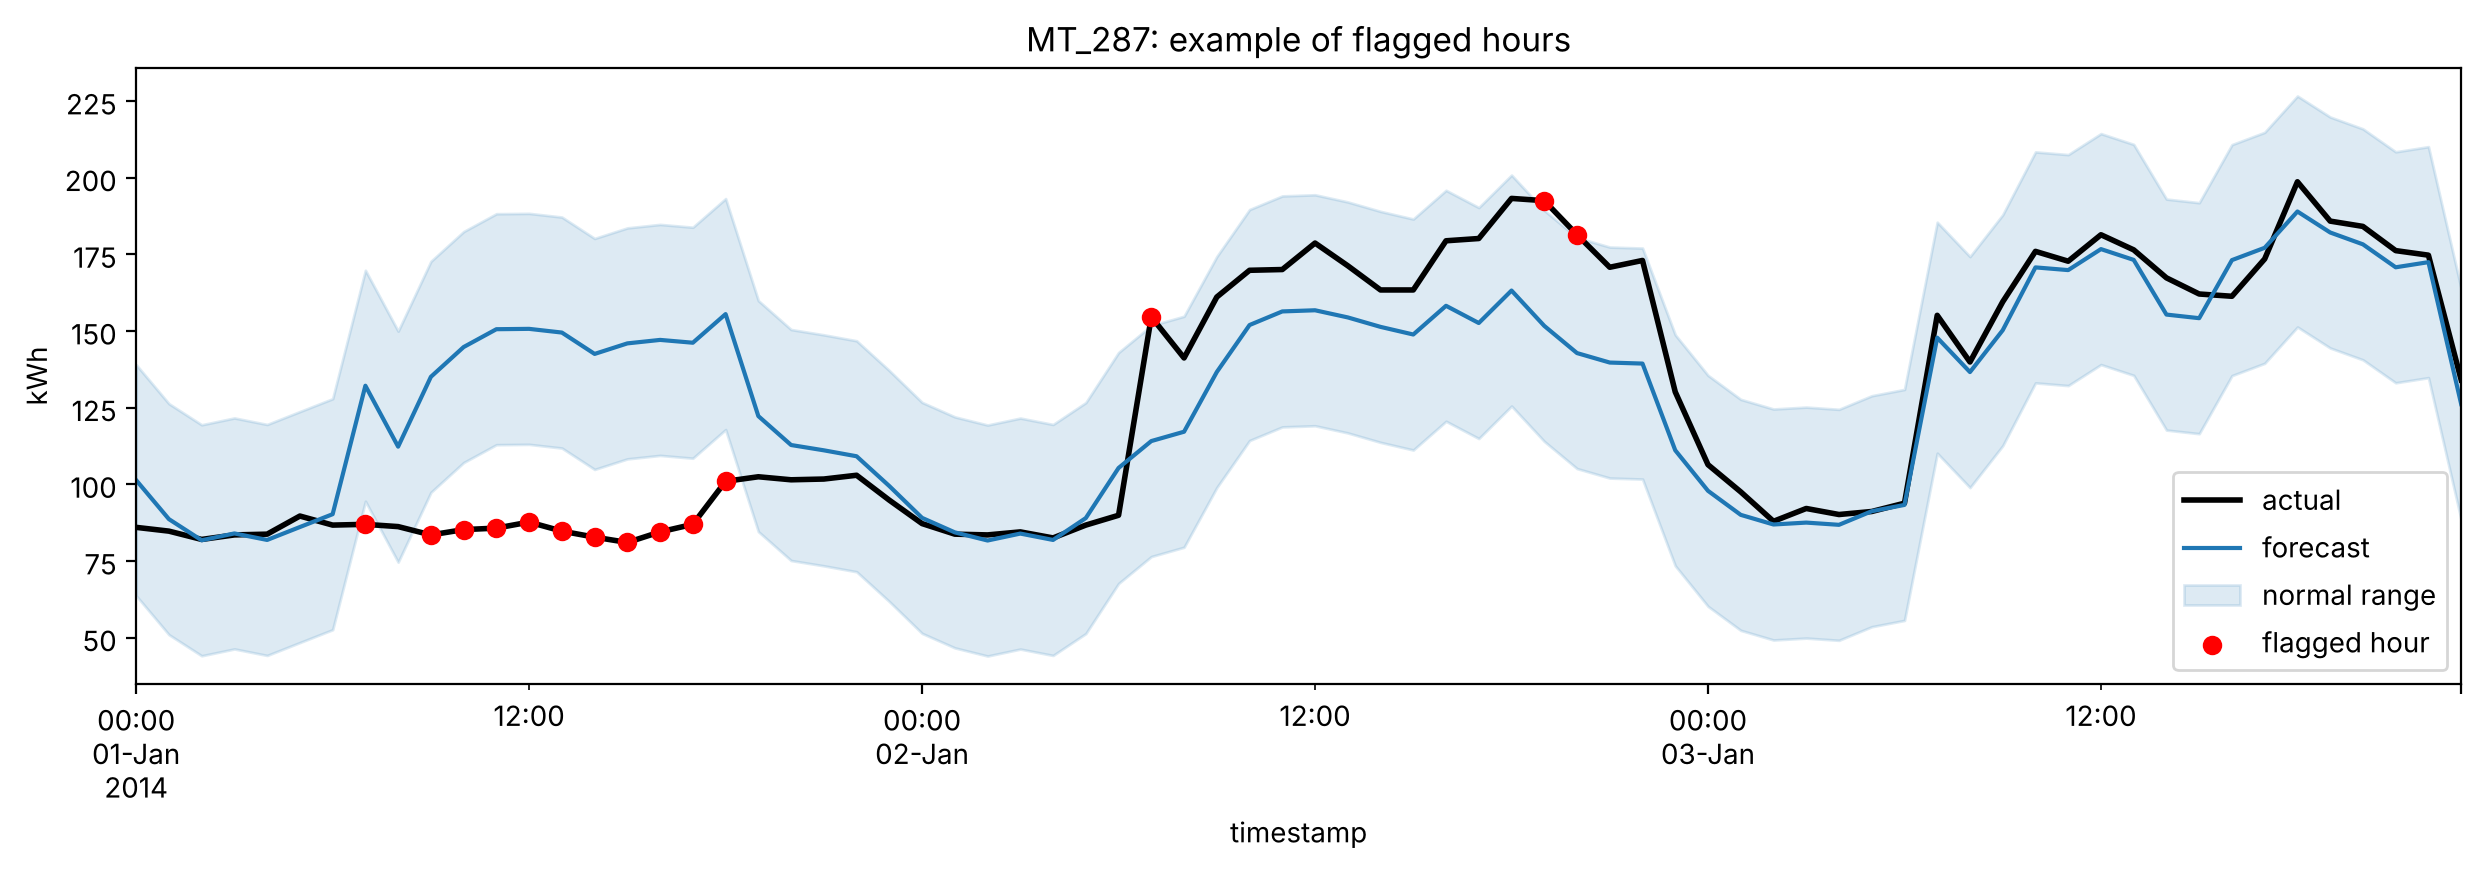

In [13]:
d = test[test.meter == m]
day = d[d.flag].index[0].normalize()
w = d.loc[day - pd.Timedelta(days=2):day + pd.Timedelta(days=2, hours=23)]
ax = w["kwh"].plot(figsize=(15, 4), color="black", lw=2, label="actual")
w["xgb"].plot(ax=ax, color="tab:blue", label="forecast")
ax.fill_between(w.index, (w.xgb - w.threshold).clip(lower=0), w.xgb + w.threshold, color="tab:blue", alpha=0.15, label="normal range")
ax.scatter(w.index[w.flag], w.kwh[w.flag], color="red", zorder=3, label="flagged hour")
ax.set_title(f"{m}: example of flagged hours"); ax.set_ylabel("kWh"); ax.legend(); plt.show()

About **1 % of the hours** in 2014 are flagged, around 8 hours per meter per month, so a person can review them. In the example, **1 January 2014** (New Year, a public holiday) is flagged: the model expected a normal working day, but the building stayed almost closed. The next morning is also flagged because the model used the holiday as "yesterday".

**Important:** the dataset has no list of real faults, so we cannot say how many flags are real problems. A flag means "this hour is unusual, please look at it", not "this is a fault". In the app, the person reviews each alert and marks it as expected or to investigate.

## 7. Save the model and the results

In [14]:
model.save_model(OUT_DIR / "models" / "xgb_forecaster.json")

meta = {
    "features": FEATURES,
    "target": "kWh / meter scale",
    "max_depth": int(best_depth),
    "trees": int(model.best_iteration + 1),
    "scale_kwh_per_meter": data.groupby("meter")["scale"].first().round(4).to_dict(),
    "alert_threshold_kwh_per_meter": (3 * val_error_std).round(4).to_dict(),
    "test_wape_percent": {"baseline": round(summary.iloc[0]["WAPE"], 2), "xgboost": round(summary.iloc[1]["WAPE"], 2)},
}
(OUT_DIR / "models" / "model_meta.json").write_text(json.dumps(meta, indent=2))

per_meter.round(3).to_csv(OUT_DIR / "test_results_per_meter.csv")
test[test.flag][["meter", "kwh", "xgb", "threshold"]].round(3).to_csv(OUT_DIR / "flagged_hours_2014.csv")
print("Saved: models/xgb_forecaster.json, models/model_meta.json, test_results_per_meter.csv, flagged_hours_2014.csv")

Saved: models/xgb_forecaster.json, models/model_meta.json, test_results_per_meter.csv, flagged_hours_2014.csv


## Summary

| Requirement | Our answer |
|---|---|
| Dataset quality and justification | Real UCI meter data, quality checks and cleaning in Notebook 1. |
| Preprocessing with no data leakage | Split by time, features at least 24 hours old, scaling from the training period only, test year used once. |
| Model and baseline | XGBoost compared with the baseline "same hour yesterday". Settings chosen on the validation set. |
| Metrics and interpretation | MAE, RMSE and WAPE per meter. On 2014 the WAPE goes from 9.3 % (baseline) to 8.5 % (XGBoost), better on 18 of 20 meters. |

The saved model `outputs/models/xgb_forecaster.json` is the one the app will use in the next evaluation.